# 03 · Vecchia prototype: how it works

This notebook walks through `r_matrix/vecchia.py` on a golden case. It covers the **sparse inverse-Cholesky** (Vecchia) approximation of C⁻¹ that design note 3 (section 2.2) proposes as an alternative to core + halo.

**The idea.** Find a sparse matrix W, lower triangular in some ordering of the data, such that

$$\tilde C^{-1} = W^\mathsf{T} W \approx C^{-1}.$$

One factor then gives the three operators we need:

| operator | use | with W |
|---|---|---|
| R⁻¹ | 4D-Var cost and gradient | WᵀW x: one halo exchange, one adjoint halo exchange |
| R^−½ | eigenProjection, dual minimisers (RPCG), which abort with spatial classes today | W x: one halo exchange |
| R^½ | EDA observation perturbations | W⁻¹ z: forward substitution |

C̃ is symmetric positive definite (SPD) **by construction**, because W has a positive diagonal. Samples x = W⁻¹z, z ~ N(0, I), have covariance exactly C̃, the matrix whose inverse 4D-Var uses.

**Two variants are prototyped.**

* **point**: the classic Vecchia (1988) / FSAI. Order the data, then regress each datum on its *m nearest earlier* neighbours.
* **block**: the R-patches are the blocks. Each patch conditions jointly on the data of *earlier* patches within h of it, a **one-sided halo**. This is block Vecchia (Katzfuss & Guinness 2021) or block FSAI (Janna et al. 2010). Its cost and communication look like those of core + halo with half the halo.

Everything runs on mock MPI tasks (`MockComm`), as in notebooks 01 and 02. Here R = C, i.e. σ = 1, as in the library.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # this checkout's r_matrix
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from r_matrix import vecchia as V, vecchia_eval as E
from r_matrix.decomposition import BisectionDecomposition
from r_matrix.geometry import points

COL = {"core+halo": "#2a78d6", "block": "#eb6834", "point": "#1baf7a", "other": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "grid.linewidth": 0.6})

## 1. The test case

`sph_geo_disc` is the SEVIRI-like golden case: 900 data in a geostationary disc with cloud gaps. It uses c = 400 km (GC support 800 km), α = 0.8 and halo h = 2.5c. We take one group and cut it into 8 patches by recursive coordinate bisection, as the library does.

n = 900, c = 400 km, alpha = 0.8, h = 1000 km, patches: [112 113 112 113 112 113 112 113]


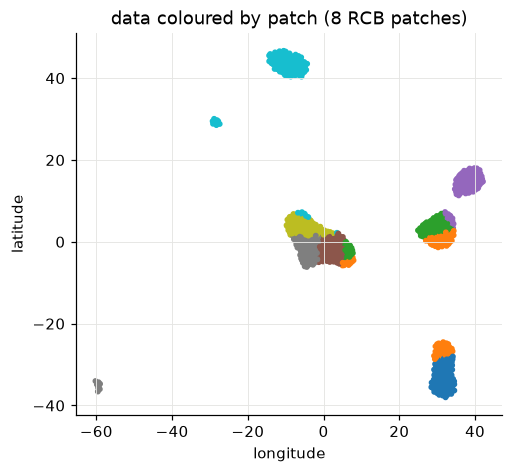

In [2]:
obs, params, hs, active = E.golden_data("sph_geo_disc")
c, alpha = params[0]; h = hs[0]
o = obs[np.argsort(obs["global_id"])]
xyz = points(o["x"], o["y"], "sphere"); gid = o["global_id"]; n = len(gid)
dec = BisectionDecomposition.from_points(o["x"], o["y"], gid, 8)
owner = dec.owner(o["x"], o["y"])
C = E.exact_C(o, c, alpha)
print(f"n = {n}, c = {c:.0f} km, alpha = {alpha}, h = {h:.0f} km, patches: {np.bincount(owner)}")
lon, lat = np.degrees(o["x"]), np.degrees(o["y"])
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(lon, lat, c=owner, cmap="tab10", s=8)
ax.set(xlabel="longitude", ylabel="latitude", title="data coloured by patch (8 RCB patches)");

## 2. Point variant, step by step

### 2.1 Ordering: max-min (coarse to fine)

`maxmin_order` is greedy farthest-point ordering. Each new datum is the one farthest from all the earlier ones. The first data cover the domain coarsely, and the later data fill it in. ℓ_k, the distance of the k-th datum to the earlier set, falls roughly like k^−½. Ties go to the smaller global ID, so the ordering is a function of the data only (D2).

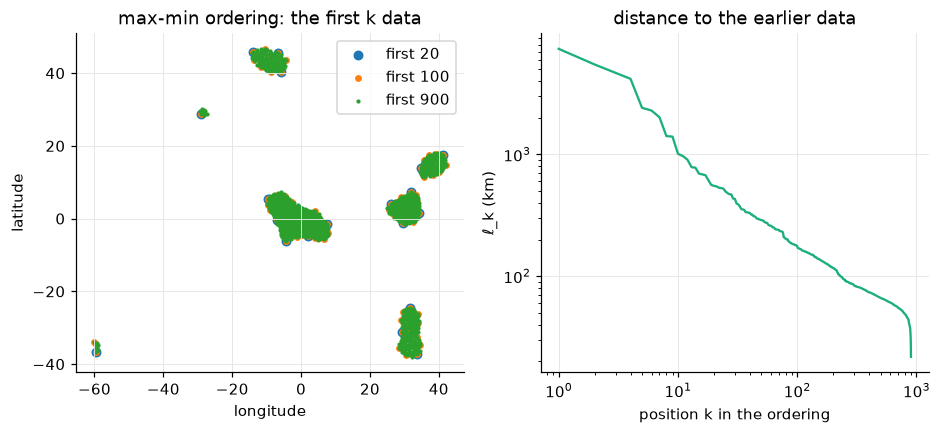

In [3]:
order, ell = V.maxmin_order(xyz, gid)
rank = V.rank_of(order)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, s in ((20, 30), (100, 12), (n, 3)):
    ax[0].scatter(lon[order[:k]], lat[order[:k]], s=s, label=f"first {k}")
ax[0].legend(); ax[0].set(title="max-min ordering: the first k data", xlabel="longitude", ylabel="latitude")
ax[1].loglog(np.arange(1, n), ell[1:], color=COL["point"])
ax[1].set(xlabel="position k in the ordering", ylabel="ℓ_k (km)", title="distance to the earlier data");

### 2.2 Neighbour sets and one conditional

For datum i, N(i) is the set of its m nearest *earlier* data, from `select_earlier`. Ties go to the smaller rank. The regression of x_i on x_N gives

$$b_i = C_{NN}^{-1} C_{N,i}, \qquad d_i = 1 - C_{i,N}\, b_i, \qquad (Wx)_i = \frac{x_i - b_i^\mathsf{T} x_{N(i)}}{\sqrt{d_i}}$$

so row i of W has m + 1 entries. Compare an early (coarse) datum with a late (fine) one. Neighbours of the late datum are close. Those of the early one are far away, because few data precede it.

datum 365: d_i = 0.2470 (the conditional variance; 1 - alpha = 0.2 is the floor set by the nugget)
b_i (nearest first): [0.1623 0.2136 0.1389 0.1931 0.1249 0.0668 0.0791 0.0387] ...
reach over all data: median 300 km, 90th percentile 2256 km, c = 400 km


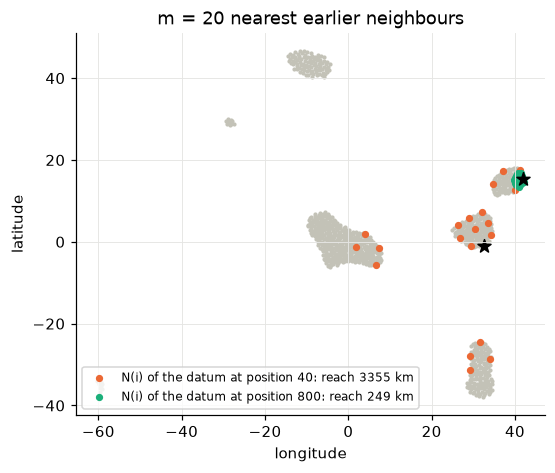

In [4]:
m = 20
nb, reach = V.point_neighbours(xyz, rank, m)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(lon, lat, s=3, color="#c3c2b7")
for k, col in ((40, COL["block"]), (800, COL["point"])):
    i = order[k]
    ax.scatter(lon[nb[i]], lat[nb[i]], s=14, color=col, label=f"N(i) of the datum at position {k}: reach {reach[i]:.0f} km")
    ax.scatter(lon[i], lat[i], s=80, marker="*", color="k")
ax.legend(fontsize=8, loc="lower left"); ax.set(title=f"m = {m} nearest earlier neighbours", xlabel="longitude", ylabel="latitude")
i = order[800]
b, d = V.point_coeffs(xyz[i], xyz[nb[i]], c, alpha)
print(f"datum {i}: d_i = {d:.4f} (the conditional variance; 1 - alpha = {1-alpha:.1f} is the floor set by the nugget)")
print("b_i (nearest first):", np.round(b[:8], 4), "...")
print(f"reach over all data: median {np.median(reach):.0f} km, 90th percentile {np.percentile(reach, 90):.0f} km, c = {c:.0f} km")

### 2.3 The factor, and its accuracy against the exact C⁻¹

We use the metric of the core + halo accuracy tests (slide 16): the generalised eigenvalues λ of C̃⁻¹C, i.e. the eigenvalues of W C Wᵀ. All λ = 1 means exact. max |λ − 1| bounds the relative error of the cost function for *any* departure vector. All λ > 0 means SPD. Also reported is the Kullback–Leibler divergence ½ Σ(λ − 1 − log λ) between N(0, C) and N(0, C̃).

With m = n − 1 the factor is the exact inverse Cholesky factor: a sanity check.

    m  max|lam-1|   lam_min         KL
    2    3.92e+00    0.0961   1.13e+02
    5    1.25e+00    0.3139   2.70e+01
   10    1.02e+00    0.4368   1.08e+01
   20    8.99e-01    0.5017   5.76e+00
   50    3.32e-01    0.6679   1.05e+00
  100    1.81e-01    0.8185   1.91e-01
  899    9.77e-15    1.0000   2.11e-27


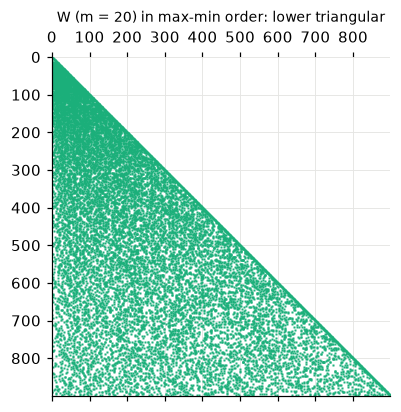

In [5]:
rows = []
for m_ in (2, 5, 10, 20, 50, 100, n - 1):
    nb_, _ = V.point_neighbours(xyz, rank, m_)
    W = V.point_W(xyz, nb_, c, alpha)
    rows.append((m_, V.eig_metrics(V.gen_eigs_W(W, C))))
print(f"{'m':>5} {'max|lam-1|':>11} {'lam_min':>9} {'KL':>10}")
for m_, r in rows:
    print(f"{m_:5d} {r['max_dev']:11.2e} {r['lam_min']:9.4f} {r['kl']:10.2e}")
W20 = V.point_W(xyz, V.point_neighbours(xyz, rank, 20)[0], c, alpha)
fig, ax = plt.subplots(figsize=(4, 4))
ax.spy(W20[order][:, order], markersize=0.3, color=COL["point"])
ax.set_title("W (m = 20) in max-min order: lower triangular", fontsize=9);

## 3. Block variant: patches as blocks, one-sided halo

The patches are put in a sequence. `patch_sequence(..., "colour")` greedily colours the patch graph, where two patches are joined if they hold data within h of each other, and then orders the patches by (colour, id). For each patch B, N(B) is the data of *earlier* patches within h of B. Then

$$S = C_{BN}C_{NN}^{-1},\quad C_{BB} - S C_{NB} = LL^\mathsf{T},\quad (Wx)_B = L^{-1}(x_B - S x_N).$$

That is one dense factorisation of size n_N + n_B per patch and group, like core + halo. The conditioning set is only the earlier side of the halo.

patch sequence: [0 2 1 3 4 5 6 7]  colours: [0 1 0 2 2 3 4 5]


block (h = 2.5 c):     max|lam-1| = 2.71e-02, one-sided halo / core = 1.29
core + halo (same h): max|lam-1| = 6.57e-02, halo / core = 2.24


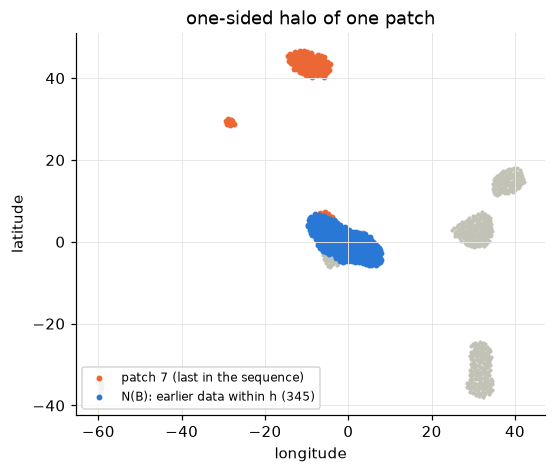

In [6]:
seq, colour = V.patch_sequence(xyz, owner, 8, h, "colour")
sets = V.block_sets(xyz, gid, owner, seq, h)
print("patch sequence:", seq, " colours:", colour)
p = seq[-1]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(lon, lat, s=3, color="#c3c2b7")
ax.scatter(lon[owner == p], lat[owner == p], s=8, color=COL["block"], label=f"patch {p} (last in the sequence)")
ax.scatter(lon[sets[p]], lat[sets[p]], s=8, color=COL["core+halo"], label=f"N(B): earlier data within h ({len(sets[p])})")
ax.legend(fontsize=8, loc="lower left"); ax.set(xlabel="longitude", ylabel="latitude", title="one-sided halo of one patch");
Wb = V.block_W(xyz, gid, owner, seq, sets, c, alpha)
A, As, sizes, cm = E.core_halo(o, dec, c, alpha, h)
print(f"block (h = {h/c:.1f} c):     max|lam-1| = {V.eig_metrics(V.gen_eigs_W(Wb, C))['max_dev']:.2e}, "
      f"one-sided halo / core = {sum(len(s) for s in sets.values()) / n:.2f}")
print(f"core + halo (same h): max|lam-1| = {V.eig_metrics(V.gen_eigs_A(As, C))['max_dev']:.2e}, "
      f"halo / core = {sum(s[1] for s in sizes) / n:.2f}")

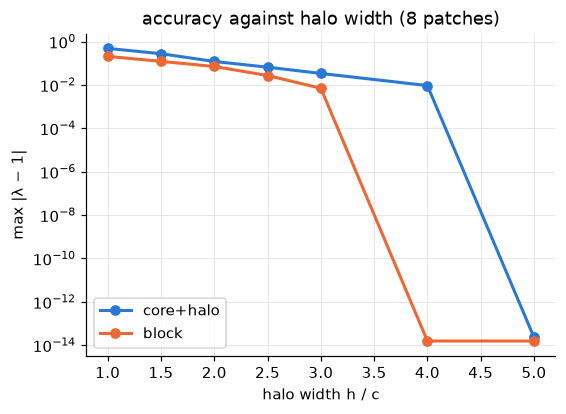

In [7]:
hcs = (1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0)
acc = {"core+halo": [], "block": []}
for hc in hcs:
    Wb_ = V.block_W(xyz, gid, owner, seq, V.block_sets(xyz, gid, owner, seq, hc * c), c, alpha)
    acc["block"].append(V.eig_metrics(V.gen_eigs_W(Wb_, C))["max_dev"])
    acc["core+halo"].append(V.eig_metrics(V.gen_eigs_A(E.core_halo(o, dec, c, alpha, hc * c)[1], C))["max_dev"])
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for k, v in acc.items():
    ax.semilogy(hcs, v, "o-", color=COL[k], lw=2, ms=6, label=k)
ax.set(xlabel="halo width h / c", ylabel="max |λ − 1|", title="accuracy against halo width (8 patches)"); ax.legend();

## 4. On mock MPI tasks

`vecchia_eval.build` runs the distributed setup on a `MockComm`, with one entry per patch.

* **point**: every patch needs the m nearest earlier neighbours of its data, but it does not know in advance how far away they are. The setup pushes the positions of all data within R of its data, starting at R0 and doubling R in each round, until every selection is **certified**: either the m-th neighbour lies within R, or R covers the sphere. A certified selection is identical to the serial one. Optionally the first `coarse` data of the ordering are replicated on all patches.
* **block**: one push of positions with radius h, and only from earlier patches to later ones.

Both then build the frozen halo communication map of notebook 01 (`commmap.build_comm_maps`), and each patch stores its rows of W as a CSR matrix over [own data; halo].

In [8]:
bp = E.build(o, dec, "point", params, m=20, order="maxmin", R0=2 * c)
bb = E.build(o, dec, "block", params, h=h, seq="colour")
print("point setup rounds:", [(f"R={r['R']:.0f} km", r["certified"]) for r in bp.info["per_round"]])
for name, b, Wser in (("point", bp, W20), ("block", bb, Wb)):
    print(f"{name}: |W_distributed - W_serial|_max = {abs(b.W() - Wser).max():.1e}")
import pandas as pd
pd.DataFrame({"point (m=20)": E.costs(bp), "block (h=2.5c)": E.costs(bb),
              "core+halo (h=2.5c)": {**E.core_halo_costs(sizes), **cm}}).T

point setup rounds: [('R=800 km', 754), ('R=1600 km', 41), ('R=3200 km', 23), ('R=6400 km', 55), ('R=12800 km', 27)]
point: |W_distributed - W_serial|_max = 0.0e+00
block: |W_distributed - W_serial|_max = 1.6e-14


,flops_setup_max,flops_setup_total,flops_apply_max,flops_apply_total,words_stored_max,halo_over_core,halo_max,peers_max,bytes_setup,collectives_setup,rounds_setup,bytes_apply,messages_apply
point (m=20),3.911493e+05,3.103220e+06,9392.0,74760.0,4809.0,0.903333,155.0,7.0,815240.0,14.0,5.0,NaN,NaN
block (h=2.5c),5.476537e+07,1.400942e+08,141344.0,476908.0,70785.0,1.288889,345.0,5.0,68644.0,6.0,1.0,NaN,NaN
core+halo (h=2.5c),4.500190e+07,1.603531e+08,1052676.0,4624336.0,131584.0,2.244444,NaN,7.0,164728.0,6.0,NaN,32320.0,72.0


### 4.1 Applying the operators

* `apply_W` does z = W x with one halo exchange.
* `apply_Wt` does y = Wᵀz: a local transposed product, then the halo part goes back to the owners with the *adjoint* halo exchange, summed in source-patch order.
* `apply_inv` is both, so the communication pattern is the same as the symmetrised core + halo operator.

The checks below: agreement with the serial matrix, and symmetry ⟨y, Ax⟩ = ⟨Ax, y⟩ to rounding.

In [9]:
def gathered(b, parts):
    out = np.zeros(n)
    for v, x in zip(b.vowned, parts):
        out[np.searchsorted(gid, v["global_id"])] = x
    return out
rng = np.random.default_rng(0)
for name, b in (("point", bp), ("block", bb)):
    x = [rng.standard_normal(len(v)) for v in b.vowned]; y = [rng.standard_normal(len(v)) for v in b.vowned]
    Ax, Ay = (gathered(b, V.apply_inv(b.comm, b.maps, b.factors, v)) for v in (x, y))
    xg, yg = gathered(b, x), gathered(b, y)
    W = b.W()
    print(f"{name}: |A x - W^T W x| = {np.abs(Ax - W.T @ (W @ xg)).max():.1e},  "
          f"<y,Ax> - <x,Ay> = {yg @ Ax - xg @ Ay:.1e} (of {yg @ Ax:.1f})")
print(pd.DataFrame(bb.comm.stats.table()).T[["calls", "bytes", "messages", "max_peers"]])

point: |A x - W^T W x| = 3.6e-15,  <y,Ax> - <x,Ay> = 0.0e+00 (of 51.7)
block: |A x - W^T W x| = 1.8e-14,  <y,Ax> - <x,Ay> = -1.5e-13 (of 43.7)
                            calls  bytes  messages  max_peers
setup:vecchia:halo:counts       1    448        56          7
setup:vecchia:halo:records      1  59076        21          6
setup:map:counts                1    448        56          7
setup:map:requests              1   9280        18          5
setup:map:confirm_counts        1    448        56          7
setup:map:confirm               1    288        18          6
recurring:halo                  2  18560        36          6
recurring:adj_halo              2  18560        36          5


### 4.2 Reproducibility (D2): independent of the number of tasks

We fix 8 patches and map them onto 1, 2, 4 and 7 tasks. R⁻¹x must be bit-identical in every case. Both builds order every reduction by (patch, global ID). The point variant with the global max-min ordering is even independent of the *patch layout*, as a matrix (W does not depend on P). Its rounding is not, though, because the adjoint sums follow the patches.

In [10]:
for variant in ("point", "block"):
    out = []
    for t in (1, 2, 4, 7):
        b = E.build(o, dec, variant, params, n_tasks=t, m=20, h=h, seq="colour")
        x = [np.random.default_rng(1).standard_normal(len(v)) for v in b.vowned]
        out.append(gathered(b, V.apply_inv(b.comm, b.maps, b.factors, x)))
    print(variant, "bit-identical on 1, 2, 4, 7 tasks:", all(np.array_equal(out[0], y) for y in out[1:]))

point bit-identical on 1, 2, 4, 7 tasks: True


block bit-identical on 1, 2, 4, 7 tasks: True


## 5. Sampling: R^½ z = W⁻¹z by forward substitution

x_B = W_BB⁻¹(z_B − W_BN x_N): a patch can compute a value once the values it conditions on are known. `sample` runs in **rounds**. In each round every patch computes what it can, then sends the new values to the patches that hold them in their halo. Rounds are sequential communication steps, so they are the cost that matters for parallel sampling.

* **Block variant with the colour sequence:** at most the number of colours.
* **Point variant with the max-min ordering:** coarse data condition on far-away data, which conditioned on others before them. The chain crosses patch boundaries many times.

In [11]:
zs = [np.random.default_rng(2).standard_normal(len(v)) for v in bp.vowned]
for name, b in (("point, max-min", bp), ("block, colour", bb),
                ("point, patch order", E.build(o, dec, "point", params, m=20, order="patch", R0=2 * c)),
                ("block, id order", E.build(o, dec, "block", params, h=h, seq="id"))):
    x, rounds = V.sample(b.comm, b.maps, b.factors, [np.random.default_rng(2).standard_normal(len(v)) for v in b.vowned])
    print(f"{name:20s}: {rounds:4d} rounds")

point, max-min      :   78 rounds
block, colour       :    5 rounds
point, patch order  :    6 rounds
block, id order     :    5 rounds


The samples have covariance exactly C̃ = (WᵀW)⁻¹. A Monte-Carlo check with 4000 samples (using the serial W):
* **Sample variances:** should match diag(C̃).
* **diag(C̃) against 1:** how close the perturbation variances are to the true error variances.
* **The sample correlation against distance:** should follow α·GC.

block: max |diag(C~) - 1| = 1.0e-05;  sample variance / diag(C~): mean 1.000 (sampling noise ~ 0.022)


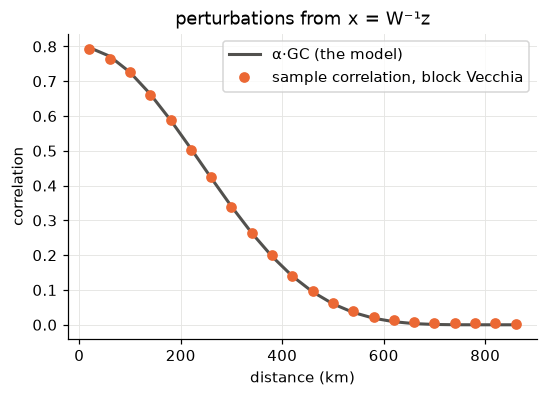

In [12]:
Wd = Wb.toarray()
o_rank = V.block_rank(gid, owner, seq)
perm = np.argsort(o_rank)
from scipy.linalg import solve_triangular
Z = np.random.default_rng(3).standard_normal((n, 4000))
X = np.empty_like(Z)
X[perm] = solve_triangular(Wd[np.ix_(perm, perm)], Z[perm], lower=True)
Ct = np.linalg.inv(Wd.T @ Wd)
print(f"block: max |diag(C~) - 1| = {np.abs(np.diag(Ct) - 1).max():.1e};  "
      f"sample variance / diag(C~): mean {np.mean(X.var(1) / np.diag(Ct)):.3f} (sampling noise ~ {np.sqrt(2/4000):.3f})")
r = V.dist(xyz, xyz)
iu = np.triu_indices(n, 1)
bins = np.linspace(0, 2.2 * c, 23)
k = np.digitize(r[iu], bins)
S = np.corrcoef(X)[iu]
mid = 0.5 * (bins[1:] + bins[:-1])
emp = [S[k == j].mean() for j in range(1, len(bins))]
from r_matrix.covariance import gaspari_cohn
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(mid, alpha * gaspari_cohn(mid, c), color="#52514e", lw=2, label="α·GC (the model)")
ax.plot(mid, emp, "o", color=COL["block"], ms=6, label="sample correlation, block Vecchia")
ax.set(xlabel="distance (km)", ylabel="correlation", title="perturbations from x = W⁻¹z"); ax.legend();

## 6. Summary of the mechanics

* Both variants give an SPD C̃ by construction, the three operators R⁻¹, R^−½ and R^½ from one factor, and results that do not depend on the task count.
* **Point:** small regressions per datum, and the apply flops are set by m. The neighbours reach far beyond the correlation support, though, so the setup needs several search rounds. With the max-min ordering, sampling needs many sequential rounds.
* **Block:** one dense factorisation per patch and group over the one-sided halo, and the communication pattern of core + halo with about half the halo. Sampling takes as many rounds as there are patch colours.

`04_vecchia_evaluation.ipynb` compares the two with core + halo on all golden cases and on real SEVIRI images at 96 to 1024 tasks.